In [16]:
import numpy as np
import pandas as pd
from matplotlib.pyplot import subplot, subplots
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (MinMaxScaler, OneHotEncoder,
                                   OrdinalEncoder, StandardScaler)
import matplotlib.pyplot as plt

##### 1. Premier regard.

In [9]:
df = pd.read_csv("atelier_connecte.csv")
df.shape #afficher les dimensions du dataframe
df.info() #Dtypes, Non-null Count
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 720 entries, 0 to 719
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   horodatage            720 non-null    str    
 1   machine_id            720 non-null    str    
 2   temperature           696 non-null    float64
 3   vibration             688 non-null    float64
 4   courant               690 non-null    float64
 5   cadence               702 non-null    float64
 6   vibration_pic         720 non-null    float64
 7   vib_f1                720 non-null    float64
 8   vib_f2                720 non-null    float64
 9   vib_f3                720 non-null    float64
 10  vib_f4                720 non-null    float64
 11  defaut                720 non-null    int64  
 12  alarme_temperature    720 non-null    int64  
 13  alarme_vibration      720 non-null    int64  
 14  alarme_courant        720 non-null    int64  
 15  alarme_cadence        720 non-null

,temperature,vibration,courant,cadence,vibration_pic,vib_f1,vib_f2,vib_f3,vib_f4,defaut,alarme_temperature,alarme_vibration,alarme_courant,alarme_cadence
count,696.000000,688.000000,690.000000,702.000000,720.000000,720.000000,720.000000,720.000000,720.000000,720.000000,720.000000,720.000000,720.000000,720.000000
mean,75.906844,2.860442,14.525110,48.817425,4.702682,1.189195,0.876973,0.514633,0.257172,0.109722,0.136111,0.155556,0.075000,0.077778
std,6.063578,1.333815,2.775327,7.370009,2.237565,0.576853,0.434318,0.265558,0.145929,0.312760,0.343145,0.362685,0.263574,0.268008
min,62.455562,0.154898,8.680389,25.152884,0.263665,0.059857,0.051620,0.050000,0.050000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,71.213711,1.797712,12.320977,43.666235,2.982704,0.758461,0.543458,0.308467,0.150378,0.000000,0.000000,0.000000,0.000000,0.000000
50%,76.126449,2.726223,14.572185,48.814309,4.403273,1.110546,0.784943,0.460895,0.223416,0.000000,0.000000,0.000000,0.000000,0.000000
75%,80.393577,3.664666,16.457567,54.709093,5.904880,1.497222,1.147989,0.682573,0.331498,0.000000,0.000000,0.000000,0.000000,0.000000
max,94.628904,7.171008,22.871525,67.536561,12.438357,3.854153,2.947193,1.661106,0.959159,1.000000,1.000000,1.000000,1.000000,1.000000


Mesures de procédé : température, vibration, courant, cadence
Spectre vibratoire : vib_f1, vib_f2, vib_f3, vib_f4, vibration_pic
Catégorie : machine_id
Alarme : alarme temperature, alarme vibration, alarme courant, alarme cadence
défaut : defaut
Autre : horodatage, donnes_synthetiques

## 2. Valeurs manquantes

In [10]:
valeur_manquante_moyenne = df.isna().mean() * 100 #moyenne des valeurs manquante

valeur_manquante_moyenne

horodatage              0.000000
machine_id              0.000000
temperature             3.333333
vibration               4.444444
courant                 4.166667
cadence                 2.500000
vibration_pic           0.000000
vib_f1                  0.000000
vib_f2                  0.000000
vib_f3                  0.000000
vib_f4                  0.000000
defaut                  0.000000
alarme_temperature      0.000000
alarme_vibration        0.000000
alarme_courant          0.000000
alarme_cadence          0.000000
donnees_synthetiques    0.000000
dtype: float64

In [11]:
col = ["temperature", "vibration", "courant", "cadence"] #les 4 colonnes avec des pannes sont les colonnes de mesures (temp, vibration, etc...)

valeurs_manquante_machine = df[col].isna().groupby(df["machine_id"]).mean() * 100
#récupère dans df les valeurs manquantes des 4 colonnes concernés, les regroupes par machines ("groupby") et en fait la moyenne ramené en pourcentage
valeurs_manquante_machine

,temperature,vibration,courant,cadence
machine_id,,,,
M-01,2.500000,5.000000,2.500000,3.333333
M-02,2.500000,7.500000,4.166667,5.833333
M-03,2.500000,3.333333,3.333333,1.666667
M-04,5.000000,4.166667,4.166667,0.833333
M-05,3.333333,3.333333,4.166667,0.833333
M-06,4.166667,3.333333,6.666667,2.500000


L'ensemble des pannes est réparti sur toutes les machines mais la machines 2 à un nombre plus important de pannes

## 3. Distributions.

Text(0, 0.5, 'nb_mesure')

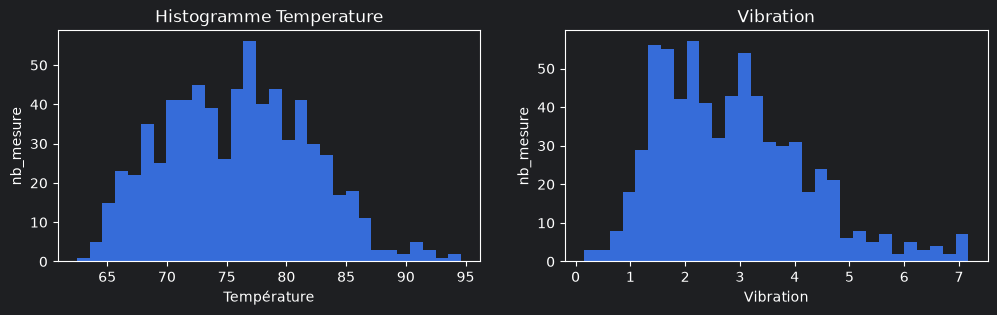

In [24]:
fig, axes = plt.subplots(1,2, figsize=(12,3))
axes[0].hist(df["temperature"].dropna(), bins=30)
axes[1].hist(df["vibration"].dropna(), bins=30)
axes[0].set_title("Histogramme Temperature")
axes[1].set_title("Vibration")
axes[0].set_xlabel("Température")
axes[1].set_xlabel("Vibration")
axes[0].set_ylabel("nb_mesure")
axes[1].set_ylabel("nb_mesure")

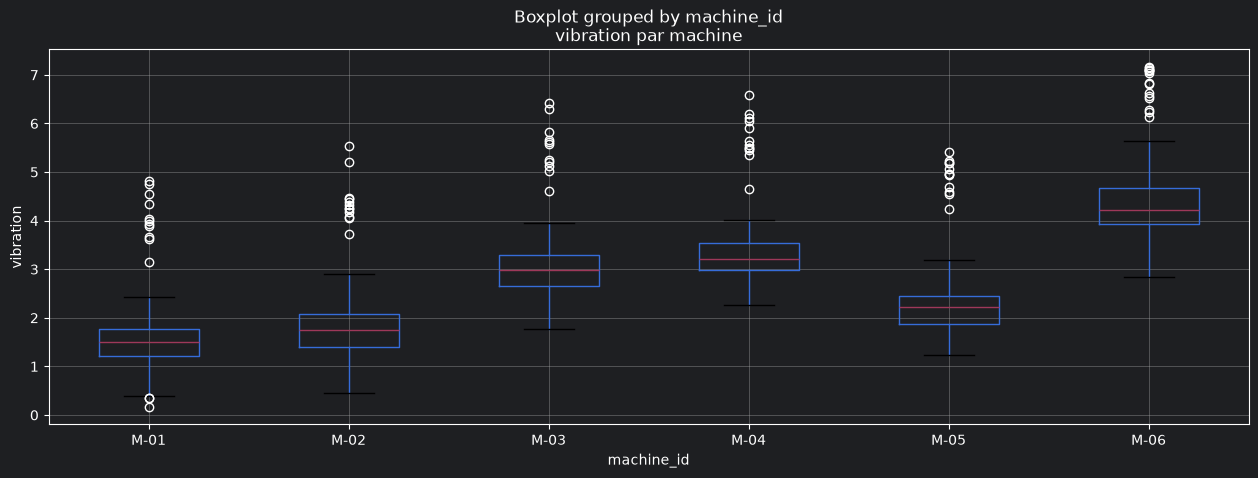

In [25]:
df.boxplot(column="vibration", by="machine_id", figsize=(15,5))
plt.title("vibration par machine")
plt.xlabel("machine_id")
plt.ylabel("vibration")
plt.show()